<img src="https://drive.google.com/uc?export=view&id=1WNLKH10YpQNNk9eeRIyYLwGkxNbNp-Mm" width="100%">

**Grupo 12**

David Martínez Triana · Andrés Ramírez Romero · David Delgado Ortiz

# Modelamiento y Evaluación
---

**Proyecto aplicado — Fase 4** (10% del proyecto)

El problema no cambió: una persona escribe una pregunta y el sistema devuelve el par pregunta-respuesta del corpus. No hay una clase que predecir ni un número que estimar.

Esta fase entrena ese recuperador, compara configuraciones y mide el resultado con consultas que no salen de recortar la pregunta oficial. El Recall@1 de **0.912** de la fase 3 comparaba representaciones con una copia acortada de la pregunta correcta. No es la nota de esta fase.

Cuatro reglas, ya medidas, quedan fijas:

- Un coseno de 1 es un empate: se muestran todos los pares que empatan.
- Un vecino bajo 0.2 no se presenta como respuesta segura.
- `fuente` sirve para filtrar y para decir de dónde sale el par. No entra al vector.
- El texto que se vectoriza es `pregunta_normalizada`.

Cada bloque va en el mismo orden: el código y, debajo, la lectura de lo que imprimió.


### **Dónde queda esta fase**

```mermaid
flowchart LR
  M["Matriz Fase 3<br/>TF-IDF palabras"] --> ENT["Entrenar / comparar"]
  ENT --> EVAL["Validación y prueba<br/>consultas paráfrasis"]
  EVAL --> APP["responder"]
  APP --> OUT["Par pregunta-respuesta"]
```

La consulta ya no es un recorte de la pregunta oficial. El 0.912 de la Fase 3 no es la nota de esta fase.


In [1]:
from pathlib import Path
import re
import shutil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

origenes = [
    Path("corpus_faq_unal_fase2_limpio.csv"),
    Path("../Entrega proyecto Fase III/corpus_faq_unal_fase2_limpio.csv"),
    Path("../Entrega proyecto Fase II/corpus_faq_unal_fase2_limpio.csv"),
]
for origen in origenes:
    if origen.exists():
        destino = Path("corpus_faq_unal_fase2_limpio.csv")
        if origen.resolve() != destino.resolve():
            shutil.copyfile(origen, destino)
        print("Corpus:", origen.resolve())
        break
else:
    raise FileNotFoundError(
        "No está corpus_faq_unal_fase2_limpio.csv. Súbalo: es el archivo que guarda la Fase 2."
    )

df = pd.read_csv("corpus_faq_unal_fase2_limpio.csv").fillna("")
print(f"Filas: {len(df)} | Fuentes: {df['fuente'].nunique()}")
print("Columnas:", list(df.columns))
print("Campo que entra al vector: pregunta_normalizada")
print("fuente, url y titulo_seccion quedan fuera del vector.")


Corpus: C:\Users\J2KUSER\Documents\Diplomado Machine learning Unal 2026\Módulo 4\Módulo 4\Entrega proyecto fase IV\corpus_faq_unal_fase2_limpio.csv
Filas: 839 | Fuentes: 22
Columnas: ['pregunta', 'respuesta', 'fuente', 'url', 'titulo_seccion', 'pregunta_normalizada', 'respuesta_normalizada', 'pregunta_texto_limpio', 'respuesta_texto_limpio']
Campo que entra al vector: pregunta_normalizada
fuente, url y titulo_seccion quedan fuera del vector.


**Explicación.** El índice tiene **839** pares y **22** fuentes, el mismo corpus limpio de la fase 2. Entrenar aquí es ajustar el vectorizador sobre esas 839 preguntas. No se aparta un grupo de filas: si un par no está en el índice, el sistema no puede devolverlo. Lo que no se ha visto es la consulta de la persona.


### **Por qué no es clasificación**

```mermaid
flowchart TD
  P["Salida deseada:<br/>un par del corpus"] --> Q{"Tipo de modelo"}
  Q --> CL["Clasificación"]
  Q --> RG["Regresión"]
  Q --> AG["Agrupamiento / tópicos"]
  Q --> RC["Recuperación<br/>vecino más cercano"]
  CL -.->|"no hay clase por fila"| X["No aplica"]
  RG -.->|"no hay valor continuo"| X
  AG -.->|"no devuelve la respuesta"| X
  RC --> OK["Coseno sobre TF-IDF"]
```


## **1. Tipo de Modelamiento**
---

La salida que se necesita es un par del corpus, no una categoría. Por eso no cabe una clasificación ni una regresión: no existe una etiqueta por fila ni un valor continuo que estimar. Un agrupamiento juntaría preguntas parecidas y un modelo de tópicos describiría temas, pero ninguno de los dos devuelve la respuesta.

El modelo es un vecino más cercano con similitud coseno. Es no supervisado: se ajusta el peso de los términos en el índice y, ante una consulta nueva, se ordenan los pares. La fase 3 dejó como referencia TF-IDF de palabras sueltas sobre `pregunta_normalizada` (839 × 1457). Esta fase no repite esa comparación con la consulta acortada. Vuelve a medir, con preguntas escritas de otra forma, si esa referencia se sostiene o si otra configuración la mejora lo suficiente para reemplazarla.

`fuente` no es una palabra de la pregunta. Meterla al vector acercaría pares de la misma dependencia aunque pregunten otra cosa, y la fase 3 ya vio que el 43.6 % de los vecinos cruzan de página. Aquí la fuente se usa después, para restringir la búsqueda o para mostrar el origen.


## **2. Implementación del modelo**
---

### **2.1. Importar Modelo**
---

La librería es scikit-learn. Se comparan ocho recuperadores. Todos buscan sobre el texto; ninguno recibe `fuente`.


In [2]:
def normalizar_texto(texto):
    """Misma normalización de la fase 2: minúsculas y un solo espacio."""
    if not isinstance(texto, str):
        return ""
    return re.sub(r"\s+", " ", texto.strip().lower())


def limpiar_con_regex(texto):
    """Misma unificación de comillas, rayas y viñetas de la fase 2."""
    if not texto:
        return ""
    t = texto
    t = re.sub(r"[\u2013\u2014\u2015]", "-", t)
    t = re.sub(r"[\u201c\u201d\u201e\u201f]", '"', t)
    t = re.sub(r"[\u2018\u2019\u201a\u201b]", "'", t)
    t = re.sub(r"\u2026", "...", t)
    t = re.sub(r"[\u2022\u2023\u2043\u2219]", " ", t)
    t = re.sub(r"[^\x00-\x7FáéíóúÁÉÍÓÚñÑüÜ\s\.,;:!?¿\-'\"°/()]", " ", t)
    return re.sub(r"\s+", " ", t).strip()


def preparar(texto):
    return limpiar_con_regex(normalizar_texto(texto))


# Palabras de función: no cuentan como solape de contenido.
PALABRAS_FUNCION = {
    "de", "la", "el", "en", "y", "a", "o", "que", "qué", "cual", "cuál",
    "como", "cómo", "los", "las", "del", "al", "un", "una", "para", "por",
    "con", "se", "su", "sus", "es", "son", "ser", "si", "no", "me", "mi",
    "mis", "le", "les", "lo", "ya", "más", "mas", "hay",
}
UMBRAL_COSENO = 0.2


def palabras_contenido(texto):
    tokens = re.findall(r"[a-záéíóúñü0-9]+", preparar(texto))
    return {t for t in tokens if t not in PALABRAS_FUNCION and len(t) > 2}


def rango_primera_relevante(scores, relevantes):
    """1 si algún par relevante empata en el primer puesto. Si no, su posición."""
    orden = np.argsort(-scores, kind="mergesort")
    mejor = float(scores[orden[0]])
    empatados = [i for i in orden if abs(float(scores[i]) - mejor) <= 1e-9]
    if any(i in relevantes for i in empatados):
        return 1
    for puesto, i in enumerate(orden, start=1):
        if i in relevantes:
            return puesto
    return None


# La referencia es la de la fase 3. Otra configuración la reemplaza solo si
# en validación le gana por más de una consulta (1/18). Con 18 preguntas,
# una diferencia menor cabe en un solo acierto.
REFERENCIA = "TF-IDF, palabras"

candidatos = [
    ("Conteos, palabras", CountVectorizer(min_df=1, ngram_range=(1, 1)), "pregunta_normalizada"),
    ("TF-IDF, palabras", TfidfVectorizer(min_df=1, ngram_range=(1, 1)), "pregunta_normalizada"),
    ("TF-IDF, min_df 2", TfidfVectorizer(min_df=2, ngram_range=(1, 1)), "pregunta_normalizada"),
    ("TF-IDF, bigramas", TfidfVectorizer(min_df=1, ngram_range=(1, 2)), "pregunta_normalizada"),
    ("TF-IDF, sublinear", TfidfVectorizer(min_df=1, ngram_range=(1, 1), sublinear_tf=True), "pregunta_normalizada"),
    ("TF-IDF, max_df 0.5", TfidfVectorizer(min_df=1, ngram_range=(1, 1), max_df=0.5), "pregunta_normalizada"),
    ("TF-IDF, caracteres 3-5", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=1), "pregunta_normalizada"),
    ("TF-IDF, sobre la respuesta", TfidfVectorizer(min_df=1, ngram_range=(1, 1)), "respuesta_normalizada"),
]

print(f"Configuraciones: {len(candidatos)}")
print("Ninguna usa la columna fuente.")
for nombre, _, campo in candidatos:
    print(f"  {nombre}: campo {campo}")


Configuraciones: 8
Ninguna usa la columna fuente.
  Conteos, palabras: campo pregunta_normalizada
  TF-IDF, palabras: campo pregunta_normalizada
  TF-IDF, min_df 2: campo pregunta_normalizada
  TF-IDF, bigramas: campo pregunta_normalizada
  TF-IDF, sublinear: campo pregunta_normalizada
  TF-IDF, max_df 0.5: campo pregunta_normalizada
  TF-IDF, caracteres 3-5: campo pregunta_normalizada
  TF-IDF, sobre la respuesta: campo respuesta_normalizada


**Explicación.** Las ocho configuraciones se ajustan sobre el mismo índice. La referencia es la de la fase 3: TF-IDF de palabras, `min_df=1`, sobre `pregunta_normalizada`. Los conteos quitan el peso IDF. `min_df=2` bota los términos que aparecen en una sola pregunta. Los bigramas y los caracteres de 3 a 5 agrandan el vocabulario. `sublinear_tf` y `max_df=0.5` cambian el peso, no el campo. La última busca en la respuesta, no en la pregunta: la fase 2 ya había visto que ese campo recupera poco, y aquí se mide otra vez con consultas nuevas.

La regla de reemplazo queda fija antes de mirar la prueba. Con 18 consultas de validación, 1/18 es el MRR de una consulta que pasa de no recuperada a recuperada de primera. Si nadie supera a la referencia por más que eso, la referencia se queda. Un empate técnico no justifica pagar 14 veces más pesos, que fue lo que costaron los caracteres en la fase 3.


### **Cómo se elige el recuperador**

```mermaid
flowchart TD
  REF["Referencia Fase 3<br/>TF-IDF palabras"] --> VAL["18 consultas de validación"]
  OTR["Otras 7 configuraciones"] --> VAL
  VAL --> CORTE{"MRR supera la referencia en más de 1 de 18"}
  CORTE -->|sí| CAMBIA["Reemplazar referencia"]
  CORTE -->|no| QUEDA["Se queda TF-IDF palabras"]
  QUEDA --> PRU["18 consultas de prueba<br/>no usadas en la elección"]
  CAMBIA --> PRU
```

El corte se fija antes de mirar la prueba. Los caracteres quedaron debajo: no cruzan 0.928 y guardan 123240 pesos.


### **2.2. Entrenamiento del Modelo y Selección de Hiperparámetros**
---

Las 36 consultas están escritas con otras palabras. No son la pregunta oficial sin artículos. El par correcto se marcó leyendo la pregunta publicada. Donde dos preguntas oficiales responden lo mismo, las dos cuentan. Dieciocho sirven para elegir. Las otras dieciocho se reservan y no entran en la elección.


In [3]:
# conjunto, consulta, preguntas oficiales que responden esa consulta
CONSULTAS = [
    ("validacion", "¿Cuántas veces puedo pedir reserva de cupo en un posgrado?", ["¿a cuántas reservas de cupo se tiene derecho durante el desarrollo de un programa de posgrado?"]),
    ("validacion", "En el buscador del SIA, ¿sirven los asteriscos o comodines?", ["¿puedo usar comodines al realizar las búsquedas?"]),
    ("validacion", "¿Hasta cuándo se reflejan las notas después de que el profesor las sube?", ["¿cuánto tardan en actualizarse las notas una vez el docente las ha ingresado?"]),
    ("validacion", "¿Cómo pido que me cancelen el semestre?", ["¿cuál es el proceso para cancelación del semestre académico?", "¿se puede solicitar la cancelación del periodo académico?"]),
    ("validacion", "¿Qué plata hay para una movilidad académica y bajo qué criterios?", ["¿cuáles son los criterios de financiación para movilidad académica?"]),
    ("validacion", "Quiero meter mi carro al campus, ¿cuántos vehículos me dejan registrar?", ["¿Cuántos vehículos puedo registrar?"]),
    ("validacion", "¿Me puedo echar para atrás después de poner una queja disciplinaria?", ["¿Después de haber radicado una queja disciplinaria puedo desistir de ella?"]),
    ("validacion", "¿El curso de Explora entrega certificado de inglés al terminar?", ["¿Al finalizar el curso se entrega algún tipo de certificado del idioma?"]),
    ("validacion", "¿Qué papeles piden para salir de movilidad desde Medellín?", ["¿Qué documentos necesito para realizar movilidad saliente?"]),
    ("validacion", "¿Cómo pido la reubicación socioeconómica en Ciencias Humanas?", ["¿Cuál es el procedimiento para el proceso de reubicación socioeconómica?", "¿Cómo hago el proceso de reubicación socioeconómica?"]),
    ("validacion", "Me llegó el correo del acta de inicio en Hermes y no sé qué sigue.", ["Recibí un correo para la aceptación del acta de inicio ¿Qué debo hacer?"]),
    ("validacion", "¿Dónde miro las normas generales que expide la Universidad?", ["¿Dónde puedo consultar la normatividad de carácter general expedida por las distintas autoridades de la Universidad Nacional de Colombia?"]),
    ("validacion", "¿Hay un mínimo de ICFES para entrar a Medicina?", ["¿HAY UN PUNTAJE MÍNIMO DEL EXAMEN DE ESTADO (ICFES-SABER 11) PARA EL INGRESO A LA FACULTAD DE MEDICINA?"]),
    ("validacion", "¿Qué significa entidad externa en el glosario de la UECP?", ["Entidad externa"]),
    ("validacion", "¿Puedo cambiar la clave del SIA?", ["¿cómo puedo cambiar mi contraseña?"]),
    ("validacion", "En el horario me aparece una materia que yo no inscribí. ¿Qué hago?", ["¿qué debo hacer si en mi horario aparece una asignatura que no inscribí?"]),
    ("validacion", "¿Quiénes integran el Consejo Superior Universitario?", ["¿Quiénes conforman el Consejo Superior Universitario?"]),
    ("validacion", "¿Se puede abrir un diplomado si no se cumplen unas condiciones?", ["¿qué condiciones deben darse para abrir un curso o diplomado?"]),
    ("prueba", "¿Cómo es el trámite para inscribirme a la ceremonia de grados?", ["¿cuál es el procedimiento para realizar la inscripción a grados?"]),
    ("prueba", "No entiendo si asignatura y curso son lo mismo en el SIA.", ["¿cuál es la diferencia entre asignatura y curso?"]),
    ("prueba", "¿Me dan un cupo extra de reserva además de los que ya tengo?", ["¿se puede solicitar una reserva de cupo adicional?", "¿cómo hago una reserva de cupo adicional?"]),
    ("prueba", "¿Cómo saco el horario en otro formato para imprimirlo?", ["¿cómo puedo cambiar la presentación de mi horario para imprimirlo?"]),
    ("prueba", "¿La página del sistema de información académica cuál es?", ["¿cuál es la página web del sistema de información académica?"]),
    ("prueba", "¿Puedo registrar la bicicleta para entrar al campus?", ["¿Puedo registrar mi bicicleta?"]),
    ("prueba", "¿Un contratista también le aplica el estatuto disciplinario?", ["¿Los contratistas son destinatarios del Estatuto Disciplinario (Acuerdo 171 de 2014 del C.S.U)?"]),
    ("prueba", "¿Puedo ver dos idiomas a la vez en Explora UN Mundo?", ["¿Es posible cursar más de un idioma dentro del programa?"]),
    ("prueba", "¿Dónde están publicadas las convocatorias de movilidad de salida?", ["¿Dónde encuentro las convocatorias para movilidad saliente?"]),
    ("prueba", "¿Los de intercambio también reciben apoyos de bienestar?", ["¿Los estudiantes de intercambio tienen acceso a los apoyos Socioeconómicos de Bienestar Universitario?"]),
    ("prueba", "¿Cómo consulto la nota del proyecto al que me presenté en Hermes?", ["¿Cómo puedo conocer la calificación del proyecto al que me postulé?"]),
    ("prueba", "Si me quedan créditos libres del pregrado, ¿me descuentan matrícula del posgrado?", ["¿Si me sobran créditos en el pregrado los puedo utilizar para el descuento de matrícula en un postgrado?"]),
    ("prueba", "¿Cuánto vale la matrícula de un pregrado?", ["¿Cuál es el costo de la matrícula de pregrado?"]),
    ("prueba", "¿Cómo pido el aval de la universidad para una convocatoria de afuera?", ["¿Cómo hago para solicitar un aval institucional para participar en una convocatoria externa?"]),
    ("prueba", "¿Qué es una ficha técnica según el glosario?", ["Ficha técnica"]),
    ("prueba", "¿Se puede pedir permiso pegado a las vacaciones?", ["¿se puede solicitar permiso antes y/o después del periodo de vacaciones?"]),
    ("prueba", "¿Cómo hago el depósito legal de un libro que publiqué?", ["¿cómo realizar el depósito legal de mi publicación?"]),
    ("prueba", "¿Cuántos cupos tiene Medicina este semestre?", ["¿CON CUÁNTOS CUPOS DISPONE LA FACULTAD DE MEDICINA PARA EL SEMESTRE?"]),
]

clave = df["pregunta_normalizada"].map(preparar)
filas_consulta = []
for conjunto, consulta, oficiales in CONSULTAS:
    relevantes = set()
    for oficial in oficiales:
        hallados = df.index[clave == preparar(oficial)].tolist()
        if not hallados:
            raise ValueError(f"No está en el corpus: {oficial}")
        relevantes.update(hallados)
    filas_consulta.append((conjunto, preparar(consulta), relevantes, consulta))

n_val = sum(c == "validacion" for c, *_ in filas_consulta)
n_prueba = sum(c == "prueba" for c, *_ in filas_consulta)
print(f"Consultas de validación: {n_val}")
print(f"Consultas de prueba: {n_prueba}")
print(f"Consultas cuya respuesta oficial ocupa más de una fila: {sum(len(r) > 1 for _, _, r, _ in filas_consulta)}")


def evaluar(vectorizador, campo, conjunto):
    """Ajusta el vectorizador en las 839 filas y mide solo las consultas del conjunto."""
    matriz = vectorizador.fit_transform(df[campo].map(preparar))
    recall_1, recall_5, reciproco = [], [], []
    for conj, consulta, relevantes, _ in filas_consulta:
        if conj != conjunto:
            continue
        scores = cosine_similarity(vectorizador.transform([consulta]), matriz).ravel()
        puesto = rango_primera_relevante(scores, relevantes)
        recall_1.append(int(puesto == 1))
        recall_5.append(int(puesto is not None and puesto <= 5))
        reciproco.append(0.0 if puesto is None else 1.0 / puesto)
    return {
        "modelo": None,
        "Recall@1": float(np.mean(recall_1)),
        "Recall@5": float(np.mean(recall_5)),
        "MRR": float(np.mean(reciproco)),
        "términos": int(len(vectorizador.get_feature_names_out())),
        "pesos": int(matriz.nnz),
    }


medidas = []
for nombre, vectorizador, campo in candidatos:
    fila = evaluar(vectorizador, campo, "validacion")
    fila["modelo"] = nombre
    medidas.append(fila)

tabla = pd.DataFrame(medidas).set_index("modelo")
mrr_ref = float(tabla.loc[REFERENCIA, "MRR"])
corte = mrr_ref + 1 / n_val
supera = tabla[tabla["MRR"] > corte]
if supera.empty:
    ganador = REFERENCIA
else:
    ganador = supera.sort_values(["MRR", "pesos"], ascending=[False, True]).index[0]

print()
print(f"MRR de la referencia en validación: {mrr_ref:.3f}")
print(f"Corte para reemplazarla: {corte:.3f} (referencia + 1/{n_val})")
print(f"Modelo elegido: {ganador}")
print()
vista = tabla.copy()
for col in ["Recall@1", "Recall@5", "MRR"]:
    vista[col] = vista[col].map(lambda v: f"{v:.3f}")
vista["elegido"] = ["sí" if i == ganador else "" for i in vista.index]
display(vista.sort_values("MRR", ascending=False))


Consultas de validación: 18
Consultas de prueba: 18
Consultas cuya respuesta oficial ocupa más de una fila: 16



MRR de la referencia en validación: 0.872
Corte para reemplazarla: 0.928 (referencia + 1/18)
Modelo elegido: TF-IDF, palabras



,Recall@1,Recall@5,MRR,términos,pesos,elegido
modelo,,,,,,
"TF-IDF, caracteres 3-5",0.833,1.000,0.889,11559,123240,
"TF-IDF, palabras",0.833,0.944,0.872,1457,8816,sí
"TF-IDF, max_df 0.5",0.833,0.944,0.872,1456,8288,
"TF-IDF, sublinear",0.833,0.944,0.871,1457,8816,
"TF-IDF, min_df 2",0.667,0.944,0.780,734,8093,
"TF-IDF, bigramas",0.611,0.833,0.704,5567,17389,
"Conteos, palabras",0.500,0.611,0.573,1457,8816,
"TF-IDF, sobre la respuesta",0.278,0.500,0.387,5011,38572,


**Explicación.** En las 18 consultas de validación la referencia queda en Recall@1 **0.833**, Recall@5 **0.944** y MRR **0.872**. Los conteos bajan a MRR **0.573**: el peso IDF sí mejora el recuperador. Buscar en la respuesta baja a **0.387**. Subir `min_df` a 2 baja a **0.780**, porque borra términos que identifican una sola pregunta. Los bigramas bajan a **0.704** y triplican los pesos.

Los caracteres de 3 a 5 llegan a MRR **0.889**. La diferencia con la referencia es **0.017**, menor que **0.056** (una consulta de 18). No cruzan el corte de **0.928**, y guardan **123240** pesos contra **8816**. No reemplazan a la referencia. `sublinear_tf` (**0.871**) y `max_df=0.5` (**0.872**) quedan en el mismo punto. El modelo que se entrena para la prueba es TF-IDF de palabras sobre `pregunta_normalizada`.


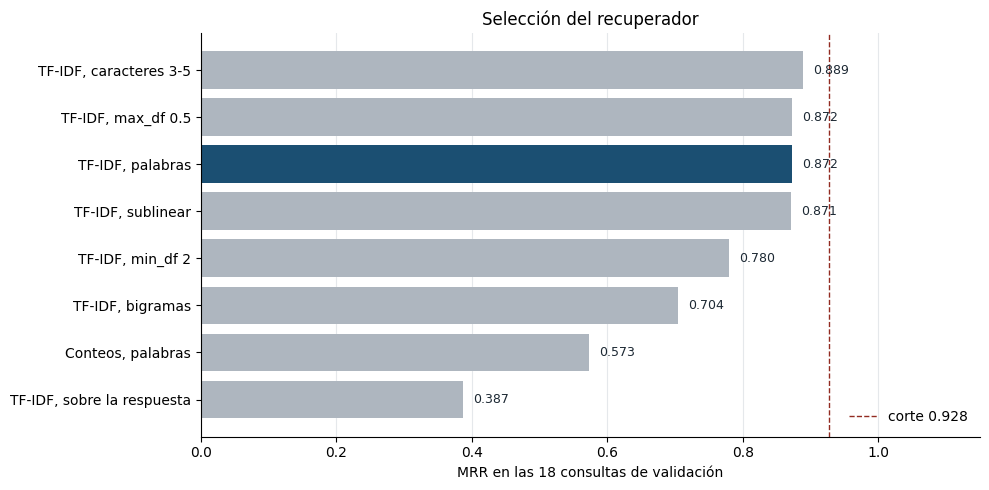

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
orden = tabla.sort_values("MRR", ascending=True)
colores = ["#1b4f72" if nombre == ganador else "#aeb6bf" for nombre in orden.index]
ax.barh(orden.index, orden["MRR"], color=colores, zorder=2)
ax.axvline(corte, color="#922b21", linestyle="--", linewidth=1, label=f"corte {corte:.3f}")
ax.set_xlim(0, 1.15)
ax.set_xlabel("MRR en las 18 consultas de validación")
ax.set_title("Selección del recuperador")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", color="#e5e8eb", zorder=0)
ax.set_axisbelow(True)
ax.legend(loc="lower right", frameon=False)
for y, valor in enumerate(orden["MRR"]):
    ax.text(valor + 0.015, y, f"{valor:.3f}", va="center", fontsize=9, color="#1c2833")
fig.tight_layout()
plt.show()


**Explicación.** La barra oscura es el modelo elegido. La línea marca el MRR que otra configuración tendría que pasar para reemplazar a la de la fase 3. Los caracteres quedan debajo de esa línea. Los conteos y la búsqueda sobre la respuesta quedan lejos, por debajo.


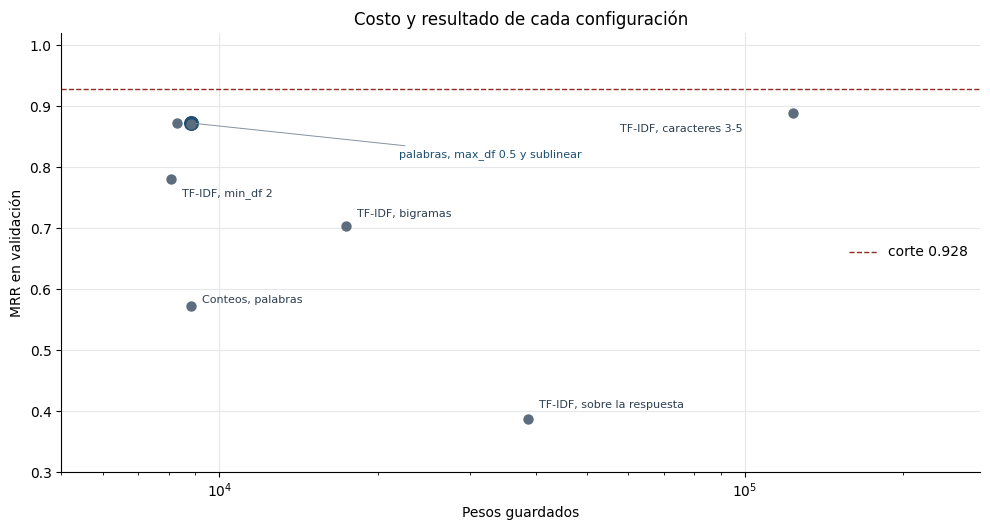

In [5]:
AZUL = "#1b4f72"
ROJO = "#922b21"
GRIS = "#aeb6bf"

fig, ax = plt.subplots(figsize=(10, 5.4))
for nombre, fila in tabla.iterrows():
    elegido = nombre == ganador
    ax.scatter(
        fila["pesos"], fila["MRR"],
        s=96 if elegido else 42,
        color=AZUL if elegido else "#5d6d7e",
        zorder=3,
    )

aislados = {
    "Conteos, palabras": (8, 2),
    "TF-IDF, min_df 2": (8, -12),
    "TF-IDF, bigramas": (8, 6),
    "TF-IDF, caracteres 3-5": (-124, -14),
    "TF-IDF, sobre la respuesta": (8, 8),
}
for nombre, xy in aislados.items():
    fila = tabla.loc[nombre]
    ax.annotate(
        nombre, (fila["pesos"], fila["MRR"]),
        textcoords="offset points", xytext=xy, fontsize=8, color="#2c3e50",
    )
ax.annotate(
    "palabras, max_df 0.5 y sublinear",
    xy=(float(tabla.loc[ganador, "pesos"]), float(tabla.loc[ganador, "MRR"])),
    xytext=(22000, 0.82),
    ha="left", va="center", fontsize=8, color=AZUL,
    arrowprops=dict(arrowstyle="-", color="#85929e", lw=0.7, shrinkA=6, shrinkB=4),
)
ax.axhline(corte, color=ROJO, linestyle="--", linewidth=1, label=f"corte {corte:.3f}")
ax.set_xscale("log")
ax.set_xlim(5000, 280000)
ax.set_ylim(0.30, 1.02)
ax.set_xlabel("Pesos guardados")
ax.set_ylabel("MRR en validación")
ax.set_title("Costo y resultado de cada configuración")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(color="#e5e8eb", zorder=0)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="center right")
fig.tight_layout()
plt.show()


**Explicación.** El punto oscuro es el modelo elegido. Queda junto a `max_df=0.5` y a `sublinear_tf`: el mismo MRR, con cerca de **8800** pesos. Los caracteres llegan a **0.889** y no cruzan el corte; guardan **123240** pesos, catorce veces la referencia. Los conteos y la búsqueda sobre la respuesta usan un costo parecido o mayor y se quedan abajo.


## **3. Evaluación o Aplicación del modelo**
---

### **3.1. Consultas no vistas**
---

El vectorizador elegido se vuelve a ajustar sobre las 839 preguntas. Las 18 consultas de prueba no se usaron para elegirlo. Al lado se mide el modelo de conteos, que ya estaba definido como punto de partida, para ver si la mejora de la validación se sostiene.


In [6]:
espec = next(item for item in candidatos if item[0] == ganador)
vectorizador = espec[1]
campo = espec[2]
matriz = vectorizador.fit_transform(df[campo].map(preparar))
print(f"Entrenamiento: {matriz.shape[0]} preguntas × {matriz.shape[1]} términos")
print(f"Pesos guardados: {matriz.nnz}")
print(f"Campo: {campo}")

conteos = next(item for item in candidatos if item[0] == "Conteos, palabras")
fila_ganador = evaluar(TfidfVectorizer(min_df=1, ngram_range=(1, 1)), campo, "prueba")
fila_ganador["modelo"] = ganador
# evaluar() reajusta un vectorizador nuevo. Se deja otra vez el oficial, el que usa la aplicación.
vectorizador = TfidfVectorizer(min_df=1, ngram_range=(1, 1))
matriz = vectorizador.fit_transform(df[campo].map(preparar))
fila_base = evaluar(CountVectorizer(min_df=1, ngram_range=(1, 1)), "pregunta_normalizada", "prueba")
fila_base["modelo"] = "Conteos, palabras"
# El conteo no pisa el vectorizador oficial: se reentrena al final de esta celda.
vectorizador = TfidfVectorizer(min_df=1, ngram_range=(1, 1))
matriz = vectorizador.fit_transform(df[campo].map(preparar))

prueba = pd.DataFrame([fila_ganador, fila_base]).set_index("modelo")
vista_prueba = prueba[["Recall@1", "Recall@5", "MRR"]].copy()
for col in vista_prueba.columns:
    vista_prueba[col] = vista_prueba[col].map(lambda v: f"{v:.3f}")
display(vista_prueba)


def detalle(conjunto):
    salidas = []
    for conj, consulta, relevantes, original in filas_consulta:
        if conj != conjunto:
            continue
        scores = cosine_similarity(vectorizador.transform([consulta]), matriz).ravel()
        orden = np.argsort(-scores, kind="mergesort")
        mejor = float(scores[orden[0]])
        empatados = [i for i in orden if abs(float(scores[i]) - mejor) <= 1e-9]
        acierto = any(i in relevantes for i in empatados)
        if acierto:
            puesto = 1
        else:
            puesto = next(p for p, i in enumerate(orden, start=1) if i in relevantes)
        salidas.append({
            "consulta": original,
            "puesto": puesto,
            "coseno": round(mejor, 3),
            "primera": df.loc[orden[0], "pregunta"],
            "fuente": df.loc[orden[0], "fuente"],
        })
    return pd.DataFrame(salidas)


detalle_prueba = detalle("prueba")
fallos = detalle_prueba[detalle_prueba["puesto"] > 1]
print(f"Consultas de prueba con el par oficial de primero: {(detalle_prueba['puesto'] == 1).sum()} de {len(detalle_prueba)}")
print(f"Consultas de prueba con coseno menor a {UMBRAL_COSENO}: {(detalle_prueba['coseno'] < UMBRAL_COSENO).sum()}")
print()
print("Prueba. Las que no quedan de primeras:")
display(fallos)

detalle_val = detalle("validacion")
fallos_val = detalle_val[detalle_val["puesto"] > 1]
print("Validación. Las que no quedan de primeras:")
display(fallos_val)


Entrenamiento: 839 preguntas × 1457 términos
Pesos guardados: 8816
Campo: pregunta_normalizada


,Recall@1,Recall@5,MRR
modelo,,,
"TF-IDF, palabras",0.833,0.944,0.880
"Conteos, palabras",0.444,0.667,0.540


Consultas de prueba con el par oficial de primero: 15 de 18
Consultas de prueba con coseno menor a 0.2: 0

Prueba. Las que no quedan de primeras:


,consulta,puesto,coseno,primera,fuente
7,¿Puedo ver dos idiomas a la vez en Explora UN ...,308,0.359,¿ Hay diferencia entre el programa de inglés d...,Explora UN Mundo
10,¿Cómo consulto la nota del proyecto al que me ...,3,0.519,¿Cómo consulto la nota definitiva?,DAMA Manizales
13,¿Cómo pido el aval de la universidad para una ...,2,0.591,¿Cómo debo solicitar el aval de la universidad...,Hermes


Validación. Las que no quedan de primeras:


,consulta,puesto,coseno,primera,fuente
1,"En el buscador del SIA, ¿sirven los asteriscos...",3,0.285,¿Sabes que es el SIA?,Estadística
8,¿Qué papeles piden para salir de movilidad des...,5,0.284,¿Dónde puedo consultar las fechas de cierre de...,ORI Medellín
11,¿Dónde miro las normas generales que expide la...,6,0.474,¿Cómo acceder a las normas NTC?,Bibliotecas — índice


**Explicación.** En las 18 consultas de prueba, que no participaron en la elección, TF-IDF de palabras queda en Recall@1 **0.833**, Recall@5 **0.944** y MRR **0.880**. Los conteos, en las mismas consultas, quedan en **0.444**, **0.667** y **0.540**. La mejora que se vio en validación se sostiene. Este número no es el 0.912 de la fase 3: allí la consulta era un recorte de la pregunta oficial.

Quince consultas recuperan un par oficial en el primer puesto. Ninguna de las 18 cae bajo 0.2: el piso no se activa con estas paráfrasis. Tres no aciertan:

- «¿Puedo ver dos idiomas a la vez en Explora UN Mundo?» queda en el puesto **308**. La primera es la diferencia entre Explora e Intensive English. La oficial («¿Es posible cursar más de un idioma dentro del programa?») usa *idioma*, en singular, y la consulta usa *idiomas*. El vector no las junta.
- «¿Cómo consulto la nota del proyecto al que me presenté en Hermes?» queda en el puesto **3**, coseno **0.519**. Arriba sale «¿Cómo consulto la nota definitiva?», de DAMA. *Nota* pesa en las dos. La oficial de Hermes queda en coseno **0.428**, dentro del Recall@5.
- «¿Cómo pido el aval de la universidad para una convocatoria de afuera?» queda en el puesto **2**, coseno **0.591**. La primera pide el aval de un grupo de investigación. La de la convocatoria externa queda justo detrás, en **0.534**.

En validación, las tres que no quedan de primeras son los comodines del SIA (puesto 3: gana «¿Sabes que es el SIA?» por la sigla), los papeles de la movilidad saliente (puesto 5: gana el cierre de la convocatoria) y las normas generales de la Universidad (puesto 6: ganan las normas NTC).


In [7]:
def wilson(aciertos, n, z=1.96):
    """Intervalo de Wilson al 95 % para una proporción."""
    prop = aciertos / n
    den = 1 + z ** 2 / n
    centro = (prop + z ** 2 / (2 * n)) / den
    margen = z * np.sqrt(prop * (1 - prop) / n + z ** 2 / (4 * n ** 2)) / den
    return prop, centro - margen, centro + margen


def ficha_de(conjunto):
    """Una fila por consulta: puesto, coseno del primero y coseno del par oficial."""
    salidas = []
    for conj, consulta, relevantes, original in filas_consulta:
        if conj != conjunto:
            continue
        scores = cosine_similarity(vectorizador.transform([consulta]), matriz).ravel()
        orden = np.argsort(-scores, kind="mergesort")
        mejor = float(scores[orden[0]])
        empatados = [i for i in orden if abs(float(scores[i]) - mejor) <= 1e-9]
        acierto = any(i in relevantes for i in empatados)
        if acierto:
            puesto = 1
        else:
            puesto = next(p for p, i in enumerate(orden, start=1) if i in relevantes)
        fuentes = sorted(df.loc[list(relevantes), "fuente"].unique())
        salidas.append({
            "conjunto": conjunto,
            "consulta": original,
            "puesto": puesto,
            "coseno": mejor,
            "coseno_oficial": max(float(scores[i]) for i in relevantes),
            "acierto": acierto,
            "fuente_primera": df.loc[orden[0], "fuente"],
            "fuentes_oficiales": " | ".join(fuentes),
        })
    return pd.DataFrame(salidas)


ficha = pd.concat([ficha_de("validacion"), ficha_de("prueba")], ignore_index=True)
vista = ficha.copy()
vista["coseno"] = vista["coseno"].map(lambda v: round(v, 3))
vista["coseno_oficial"] = vista["coseno_oficial"].map(lambda v: round(v, 3))
vista["acierto"] = vista["acierto"].map(lambda v: "sí" if v else "no")

print("Las 36 consultas, con el puesto del par oficial.")
with pd.option_context("display.max_rows", 40, "display.max_colwidth", 68):
    display(vista[[
        "conjunto", "puesto", "coseno", "coseno_oficial", "acierto",
        "fuente_primera", "fuentes_oficiales", "consulta",
    ]])

prueba = ficha[ficha["conjunto"] == "prueba"]
aciertos = int(prueba["acierto"].sum())
prop, bajo, alto = wilson(aciertos, len(prueba))
print(f"Recall@1 en prueba: {aciertos}/{len(prueba)} = {prop:.3f}")
print(f"Intervalo de Wilson al 95 %: {bajo:.3f} a {alto:.3f}")

reciproco = 1 / prueba["puesto"].to_numpy()
rng = np.random.default_rng(12)
muestras = [reciproco[rng.integers(0, len(reciproco), len(reciproco))].mean() for _ in range(4000)]
print(f"MRR en prueba: {reciproco.mean():.3f}")
print(f"Intervalo por remuestreo de las 18 consultas, al 95 %: {np.quantile(muestras, 0.025):.3f} a {np.quantile(muestras, 0.975):.3f}")
print(f"Coseno del primer par en prueba: mínimo {prueba['coseno'].min():.3f}, mediana {prueba['coseno'].median():.3f}, máximo {prueba['coseno'].max():.3f}")

print()
print("Prueba, por las fuentes del par oficial.")
por_fuente = (
    prueba.groupby("fuentes_oficiales")
    .agg(aciertos=("acierto", "sum"), consultas=("acierto", "count"))
    .astype(int)
    .sort_values(["aciertos", "consultas", "fuentes_oficiales"])
)
display(por_fuente)


Las 36 consultas, con el puesto del par oficial.


,conjunto,puesto,coseno,coseno_oficial,acierto,fuente_primera,fuentes_oficiales,consulta
0,validacion,1,0.372,0.372,sí,Ingeniería Bogotá,Estadística | Ingeniería Bogotá,¿Cuántas veces puedo pedir reserva de cupo en un posgrado?
1,validacion,3,0.285,0.255,no,Estadística,DAMA Manizales | SIAPAL,"En el buscador del SIA, ¿sirven los asteriscos o comodines?"
2,validacion,1,0.295,0.295,sí,SIAPAL,DAMA Manizales | SIAPAL,¿Hasta cuándo se reflejan las notas después de que el profesor l...
3,validacion,1,0.347,0.347,sí,Humanas — Bienestar,Estadística | Humanas — Bienestar | Ingeniería Bogotá,¿Cómo pido que me cancelen el semestre?
4,validacion,1,0.531,0.531,sí,Ingeniería Bogotá,Estadística | Ingeniería Bogotá,¿Qué plata hay para una movilidad académica y bajo qué criterios?
5,validacion,1,0.638,0.638,sí,Gestión vehicular,Gestión vehicular,"Quiero meter mi carro al campus, ¿cuántos vehículos me dejan reg..."
6,validacion,1,0.585,0.585,sí,Veeduría disciplinaria Medellín,Veeduría disciplinaria Medellín,¿Me puedo echar para atrás después de poner una queja disciplina...
7,validacion,1,0.489,0.489,sí,Explora UN Mundo,Explora UN Mundo,¿El curso de Explora entrega certificado de inglés al terminar?
8,validacion,5,0.284,0.209,no,ORI Medellín,ORI Medellín,¿Qué papeles piden para salir de movilidad desde Medellín?
9,validacion,1,0.680,0.680,sí,Estadística,Estadística | Humanas — Bienestar,¿Cómo pido la reubicación socioeconómica en Ciencias Humanas?


Recall@1 en prueba: 15/18 = 0.833
Intervalo de Wilson al 95 %: 0.608 a 0.942
MRR en prueba: 0.880
Intervalo por remuestreo de las 18 consultas, al 95 %: 0.732 a 1.000
Coseno del primer par en prueba: mínimo 0.306, mediana 0.498, máximo 0.876

Prueba, por las fuentes del par oficial.


,aciertos,consultas
fuentes_oficiales,,
Explora UN Mundo,0,1
Hermes,0,2
Bibliotecas sede Bogotá | Bibliotecas — índice,1,1
Dirección de Personal | Personal académico,1,1
Estadística,1,1
Gestión vehicular,1,1
Humanas — Bienestar,1,1
Ingeniería UECP — Glosario,1,1
Medicina Bogotá,1,1


**Explicación.** La tabla lista las 36 consultas. `coseno` es el del primer par. `coseno_oficial` es el del par que responde la pregunta. Cuando coinciden, el acierto es sí.

En la prueba son **15 de 18**. El Recall@1 de **0.833** tiene un intervalo de Wilson al 95 % de **0.608 a 0.942**. El MRR de **0.880**, al remuestrear esas 18 consultas, queda entre **0.732 y 1.000**. La subida frente a los conteos se ve en la tabla anterior. El intervalo dice que 18 consultas no separan un 0.75 de un 0.90. La mediana del primer coseno en la prueba es **0.498**. Ninguna baja de **0.306**.

Por fuente oficial, en la prueba, Hermes queda **0 de 2**: la nota del proyecto y el aval. Explora queda **0 de 1**: los dos idiomas. DAMA Manizales con SIAPAL queda **3 de 3**.


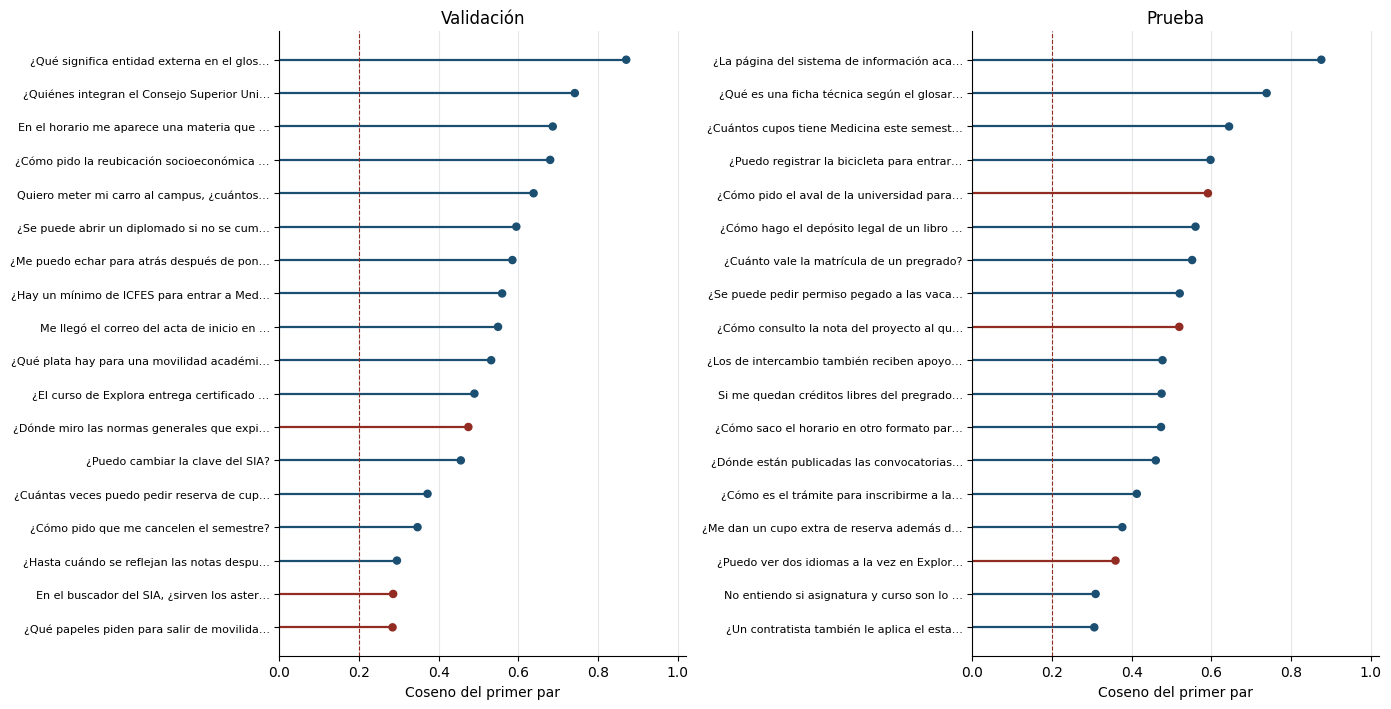

In [8]:
def panel_consultas(ax, sub, titulo):
    sub = sub.sort_values(["coseno", "consulta"])
    y = np.arange(len(sub))
    colores = [AZUL if valor else ROJO for valor in sub["acierto"]]
    ax.hlines(y, 0, sub["coseno"], color=colores, linewidth=1.6)
    ax.scatter(sub["coseno"], y, c=colores, s=26, zorder=3)
    ax.axvline(UMBRAL_COSENO, color=ROJO, linestyle="--", linewidth=0.8)
    etiquetas = [texto if len(texto) <= 42 else texto[:41] + "…" for texto in sub["consulta"]]
    ax.set_yticks(y)
    ax.set_yticklabels(etiquetas, fontsize=8)
    ax.set_xlim(0, 1.02)
    ax.set_xlabel("Coseno del primer par")
    ax.set_title(titulo)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="x", color="#e5e8eb", zorder=0)
    ax.set_axisbelow(True)


fig, ejes = plt.subplots(1, 2, figsize=(14, 7.2))
panel_consultas(ejes[0], ficha[ficha["conjunto"] == "validacion"], "Validación")
panel_consultas(ejes[1], ficha[ficha["conjunto"] == "prueba"], "Prueba")
fig.tight_layout()
plt.show()


**Explicación.** Cada línea es una consulta y el punto es el coseno de su primer par. Azul: ese par es el oficial. Rojo: no lo es. La línea punteada es **0.2**. Las 36 quedan a la derecha. En la prueba los tres rojos son el aval, la nota del proyecto en Hermes y los dos idiomas. En validación son las normas generales, los comodines del SIA y los papeles de la movilidad.


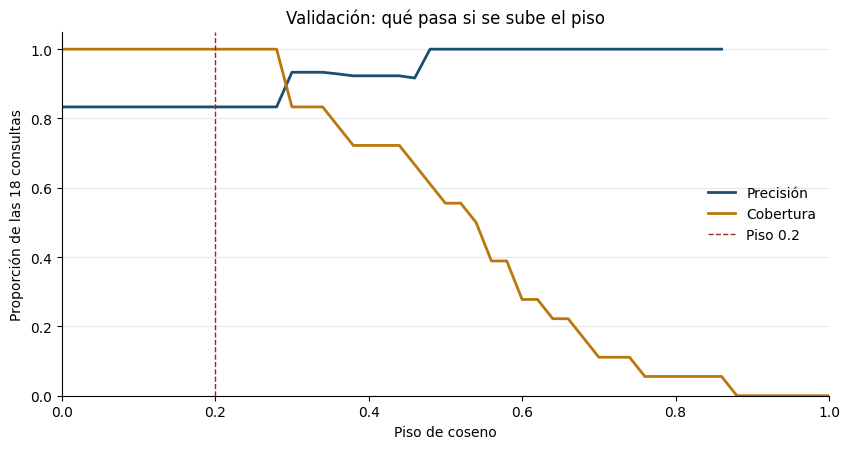

Piso 0.2: se responden 18 de 18, precisión 0.833
Piso 0.3: se responden 15 de 18, precisión 0.933
Piso 0.5: se responden 10 de 18, precisión 1.000


In [9]:
validacion = ficha[ficha["conjunto"] == "validacion"]
umbrales = np.round(np.arange(0, 1.001, 0.02), 2)
precision, cobertura = [], []
for piso in umbrales:
    pasan = validacion["coseno"] >= piso
    cobertura.append(float(pasan.mean()))
    precision.append(float(validacion.loc[pasan, "acierto"].mean()) if pasan.any() else np.nan)

fig, ax = plt.subplots(figsize=(8.6, 4.6))
ax.plot(umbrales, precision, color=AZUL, linewidth=2, label="Precisión")
ax.plot(umbrales, cobertura, color="#b9770e", linewidth=2, label="Cobertura")
ax.axvline(UMBRAL_COSENO, color=ROJO, linestyle="--", linewidth=1, label="Piso 0.2")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.set_xlabel("Piso de coseno")
ax.set_ylabel("Proporción de las 18 consultas")
ax.set_title("Validación: qué pasa si se sube el piso")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="#e5e8eb", zorder=0)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="center right")
fig.tight_layout()
plt.show()

for piso in (0.2, 0.3, 0.5):
    pasan = validacion["coseno"] >= piso
    prec = validacion.loc[pasan, "acierto"].mean()
    print(f"Piso {piso:.1f}: se responden {int(pasan.sum())} de {len(validacion)}, precisión {prec:.3f}")


**Explicación.** La curva usa solo la validación. En **0.2** se responden las **18** y la precisión sigue en **0.833**: el piso no separa aciertos de errores en estas paráfrasis. En **0.3** se responden **15** y la precisión sube a **0.933**. En **0.5** la precisión es **1** y se responden **10 de 18**. El piso no se mueve. Quedó en 0.2 porque un vecino por debajo de ese valor no se presenta como respuesta segura. Subirlo aquí dejaría fuera consultas que sí daban el par oficial.


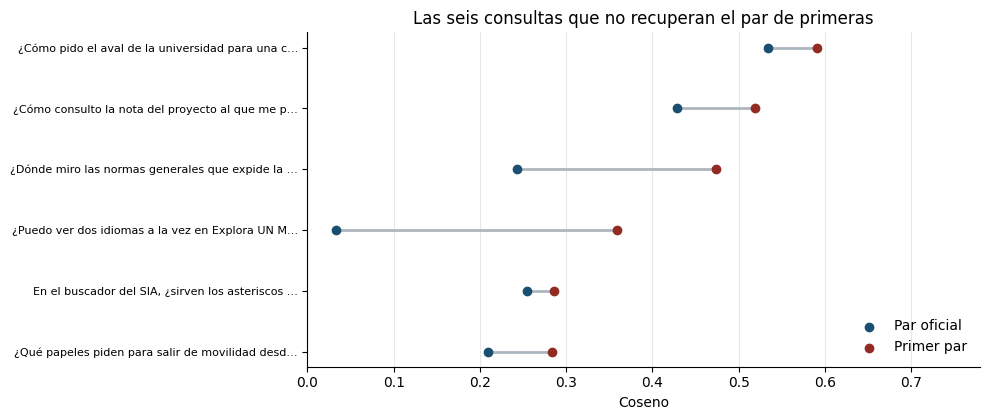

In [10]:
fallos = ficha[ficha["acierto"] == False].sort_values("coseno")
fig, ax = plt.subplots(figsize=(10, 4.3))
y = np.arange(len(fallos))
for i, (_, fila) in enumerate(fallos.iterrows()):
    ax.plot([fila["coseno_oficial"], fila["coseno"]], [i, i], color=GRIS, linewidth=2, zorder=1)
ax.scatter(fallos["coseno_oficial"], y, s=36, color=AZUL, zorder=3, label="Par oficial")
ax.scatter(fallos["coseno"], y, s=36, color=ROJO, zorder=3, label="Primer par")
etiquetas = [texto if len(texto) <= 48 else texto[:47] + "…" for texto in fallos["consulta"]]
ax.set_yticks(y)
ax.set_yticklabels(etiquetas, fontsize=8)
ax.set_xlim(0, 0.78)
ax.set_xlabel("Coseno")
ax.set_title("Las seis consultas que no recuperan el par de primeras")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", color="#e5e8eb", zorder=0)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
plt.show()


**Explicación.** El punto azul es el par oficial y el rojo es el que quedó primero. El aval queda en **0.534** contra **0.591**, y la nota del proyecto en **0.428** contra **0.519**: otra pregunta del corpus habla de lo mismo con otras palabras. Los dos idiomas quedan lejos, **0.033** contra **0.359**, porque la consulta dice *idiomas* y la fila oficial dice *idioma*. Normas, comodines y papeles quedan en medio: el oficial existe, y otra fila comparte una palabra más visible.


### **Cómo responde el sistema**

```mermaid
flowchart TD
  Q["Consulta de la persona"] --> V["Vectorizar con el TF-IDF"]
  V --> C["Coseno contra las 839"]
  C --> F{"Filtro por fuente"}
  F -->|sí| AP["Apagar otras fuentes"]
  F -->|no| TOP["Tomar el primer puesto"]
  AP --> TOP
  TOP --> E{"Coseno igual a 1"}
  E -->|sí| EMP["Mostrar todos los empates"]
  E -->|no| U{"Coseno bajo 0.2"}
  U -->|sí| NO1["No se presenta como segura"]
  U -->|no| S{"Solape de contenido menor que 2"}
  S -->|sí| NO2["No se presenta como segura"]
  S -->|no| OK["Entregar el par"]
```

`fuente` filtra después del coseno. No entra al vector.


### **3.2. Aplicación**
---

`responder` ordena el índice, entrega todos los pares que empatan en el primer coseno y aplica las dos reglas de prudencia. `fuente`, si se pide, apaga las filas de las demás dependencias después de calcular el coseno.


In [11]:
def responder(consulta, fuente=None):
    """Devuelve los pares empatados en el primer puesto. fuente solo filtra."""
    scores = cosine_similarity(vectorizador.transform([preparar(consulta)]), matriz).ravel().copy()
    if fuente is not None:
        scores[df["fuente"].to_numpy() != fuente] = -1.0
    if float(scores.max()) < 0:
        return pd.DataFrame(), "esa fuente no tiene pares en el índice"
    mejor = float(scores.max())
    orden = np.argsort(-scores, kind="mergesort")
    # Bajo 0.2 no hay respuesta. Un coseno 0 empataría las 839 filas: se muestra una sola.
    if mejor < UMBRAL_COSENO:
        indices = [int(orden[0])]
        aviso = "no se presenta como respuesta segura: el coseno está bajo 0.2"
    else:
        indices = [int(i) for i in orden if abs(float(scores[i]) - mejor) <= 1e-9]
        aviso = None
    filas = []
    for i in indices:
        solape = palabras_contenido(consulta) & palabras_contenido(df.loc[i, "pregunta"])
        filas.append({
            "coseno": round(float(scores[i]), 3),
            "fuente": df.loc[i, "fuente"],
            "solape": len(solape),
            "pregunta": df.loc[i, "pregunta"],
            "respuesta": df.loc[i, "respuesta"][:280],
        })
    tabla_resp = pd.DataFrame(filas)
    if aviso:
        return tabla_resp, aviso
    if int(tabla_resp["solape"].min()) < 2:
        return tabla_resp, "no se presenta como respuesta segura: comparte menos de dos palabras de contenido"
    aviso = "empate: se muestran todos los pares del primer puesto" if len(tabla_resp) > 1 else "un par en el primer puesto"
    return tabla_resp, aviso


print("1. Paráfrasis de la prueba. Medicina, cupos del semestre.")
tabla_resp, aviso = responder("¿Cuántos cupos tiene Medicina este semestre?")
print(aviso)
display(tabla_resp)

print()
print("2. La misma pregunta está publicada más de una vez. Coseno 1: empate.")
tabla_resp, aviso = responder("¿Se puede solicitar la cancelación del periodo académico?")
print(aviso)
display(tabla_resp[["coseno", "fuente", "pregunta"]])
textos = tabla_resp["respuesta"].map(lambda texto: " ".join(texto.split()))
print(f"Respuestas distintas en el empate: {textos.nunique()} de {len(textos)} filas")
for fuente, texto in zip(tabla_resp["fuente"], textos):
    print(f"- {fuente}: {texto[:170]}")

print()
print("3. La misma consulta, filtrada a Estadística. fuente no entra al vector.")
tabla_resp, aviso = responder(
    "¿Se puede solicitar la cancelación del periodo académico?",
    fuente="Estadística",
)
print(aviso)
display(tabla_resp[["coseno", "fuente", "pregunta"]])

print()
print("4. Paráfrasis con dos copias idénticas en el índice.")
tabla_resp, aviso = responder("¿Puedo cambiar la clave del SIA?")
print(aviso)
display(tabla_resp[["coseno", "fuente", "solape", "pregunta"]])

print()
print("5. Consulta sin palabras del corpus.")
tabla_resp, aviso = responder("xyzqqq plántula marciana")
print(aviso)
display(tabla_resp[["coseno", "fuente", "pregunta"]])

print()
print("6. Consulta fuera de tema que igual supera 0.2 por las palabras de función.")
tabla_resp, aviso = responder("¿Cuál es el menú del almuerzo de hoy en la cafetería?")
print(aviso)
display(tabla_resp[["coseno", "fuente", "solape", "pregunta"]])

print()
print("7. El glosario entra si la consulta lo pide. La fuente se muestra, no se vectoriza.")
tabla_resp, aviso = responder("¿Qué significa entidad externa en el glosario de la UECP?")
print(aviso)
display(tabla_resp[["coseno", "fuente", "solape", "pregunta"]])


1. Paráfrasis de la prueba. Medicina, cupos del semestre.
un par en el primer puesto


,coseno,fuente,solape,pregunta,respuesta
0,0.644,Medicina Bogotá,4,¿CON CUÁNTOS CUPOS DISPONE LA FACULTAD DE MEDI...,Cada semestre se ofertan cerca de 100 cupos pa...



2. La misma pregunta está publicada más de una vez. Coseno 1: empate.
empate: se muestran todos los pares del primer puesto


,coseno,fuente,pregunta
0,1.0,Ingeniería Bogotá,¿Se puede solicitar la cancelación del periodo...
1,1.0,Ingeniería Bogotá,¿Se puede solicitar la cancelación del periodo...
2,1.0,Estadística,¿Se puede solicitar la cancelación del periodo...


Respuestas distintas en el empate: 3 de 3 filas
- Ingeniería Bogotá: Sí, en caso de fuerza mayor, o caso fortuito. Se debe realizar la solicitud a través del SIA en la opción "Cancelación período académico", o mediante el formulario web. L
- Ingeniería Bogotá: Sí, en caso de fuerza mayor o caso fortuito. Se debe presentar la solicitud al Consejo de Facultad antes de haberse consolidado la nota definitiva de las asignaturas que 
- Estadística: Sí, La cancelación del periodo académico le permite al estudiante matriculado, cancelar la totalidad de la carga académica, cuando por causas de fuerza mayor o caso fortu

3. La misma consulta, filtrada a Estadística. fuente no entra al vector.
un par en el primer puesto


,coseno,fuente,pregunta
0,1.0,Estadística,¿Se puede solicitar la cancelación del periodo...


... (4 outputs left out)


6. Consulta fuera de tema que igual supera 0.2 por las palabras de función.
no se presenta como respuesta segura: comparte menos de dos palabras de contenido


,coseno,fuente,solape,pregunta
0,0.502,Estadística,0,¿Cuál es la duración del programa de la Especi...



7. El glosario entra si la consulta lo pide. La fuente se muestra, no se vectoriza.
un par en el primer puesto


,coseno,fuente,solape,pregunta
0,0.87,Ingeniería UECP — Glosario,2,Entidad externa


**Explicación.** La consulta de los cupos de Medicina devuelve un solo par, de Medicina Bogotá, y se presenta como respuesta: el coseno pasa de 0.2 y hay más de una palabra de contenido en común.

La cancelación del periodo académico está tres veces en el índice, dos en Ingeniería Bogotá y una en Estadística. El coseno es **1** en las tres. El sistema no se queda con una. Las tres respuestas no dicen el mismo trámite: Ingeniería trae una vía por el SIA o el formulario y otra ante el Consejo de Facultad; Estadística describe la cancelación de toda la carga. El empate se entrega entero para no esconder esa diferencia. Al filtrar `fuente="Estadística"` queda solo ese par, con el mismo coseno: el filtro apaga filas, no cambia el vector. La clave del SIA está en SIAPAL y en DAMA Manizales con la misma pregunta, así que la paráfrasis también empata y se muestran las dos.

«xyzqqq plántula marciana» no comparte términos con el índice. El coseno es **0**. Se enseña un solo vecino para ver el número, y no se entrega como respuesta: si se tratara como empate, las 839 filas quedarían de primeras. El menú de la cafetería sí pasa de 0.2, porque «cuál» y «es» pesan en muchas preguntas, pero el solape de contenido es **0**. Tampoco se presenta como respuesta segura. En las 18 de validación, cuatro consultas comparten menos de dos palabras de contenido con su primer vecino: dos son errores (los comodines y las normas) y dos son aciertos reales (las notas y la cancelación del semestre). La regla es prudente y, en esos dos aciertos, deja de llamar segura una respuesta que sí era la oficial.

«Entidad externa» devuelve el glosario de la UECP. La fuente se lee en la tabla. No hizo falta meterla al vector para saber de dónde sale.


### **Qué queda de esta fase**

El objetivo de la fase es entrenar un recuperador acorde a este corpus y mejorar su desempeño con una comparación. No es clasificar la pregunta. Quedó cumplido.

El modelo se ajusta sobre las **839** preguntas. Ante una consulta escrita con otras palabras, devuelve un par del índice. En las 18 consultas de prueba, que no entraron en la elección, el MRR pasa de **0.540** con conteos a **0.880** con TF-IDF de palabras. Buscar en la respuesta se queda en **0.387** en validación, así que el campo sigue siendo la pregunta. `max_df`, `sublinear_tf` y los caracteres quedan al lado de la referencia y no la reemplazan: no cruzan el corte fijado antes de mirar la prueba.

Quince de esas 18 recuperan el par oficial de primero, y 17 lo dejan entre los cinco primeros. Las tres que no —los dos idiomas, la nota del proyecto y el aval— están impresas. El Recall@1 de **0.833** tiene un intervalo de **0.608 a 0.942**: la fase mide el modelo, y esa medida cabe en un rango ancho porque son 18 consultas.

- El modelo entregado es TF-IDF de palabras, `min_df=1`, sobre `pregunta_normalizada`. Matriz **839 × 1457**, **8816** pesos.
- El 0.912 de la fase 3 no es esta medida. Allá la consulta era un recorte de la pregunta oficial.
- Un coseno de 1 se devuelve completo, también cuando las respuestas no coinciden. Un coseno bajo 0.2, o un solape de menos de dos palabras de contenido, no se presenta como respuesta segura.
- `fuente` filtra y se muestra. No es un término del vector.


## **Créditos**

* **Profesor:** [Felipe Restrepo Calle](https://dis.unal.edu.co/~ferestrepoca/)
* **Asistentes docentes:**
    - [Juan Sebastián Lara Ramírez](https://www.linkedin.com/in/juan-sebastian-lara-ramirez-43570a214/).
* **Diseño de imágenes:**
    - [Rosa Alejandra Superlano Esquibel](mailto:rsuperlano@unal.edu.co).
* **Coordinador de virtualización:**
    - [Edder Hernández Forero](https://www.linkedin.com/in/edder-hernandez-forero-28aa8b207/).

**Universidad Nacional de Colombia** - *Facultad de Ingeniería*
